In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/retail_sales_dataset.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:

# 1. Check column names and data types
print("DATASET INFORMATION")
df.info()

# 2. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 4. Check numerical statistics
print("\nNUMERICAL SUMMARY")
display(df.describe())

# 5. Check unique values in categorical columns
print("\nCATEGORICAL VALUE COUNTS")

for col in ['Gender', 'Product Category']:
    print(f"\n{col}:")
    print(df[col].value_counts())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

MISSING VALUES
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

DUPLICATE ROWS
0

NUMERICAL SUMMARY


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



CATEGORICAL VALUE COUNTS

Gender:
Gender
Female    510
Male      490
Name: count, dtype: int64

Product Category:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64


In [3]:

# Convert Date from text to datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Check whether any dates could not be converted
print("Invalid dates:", df['Date'].isna().sum())

# Check whether Total Amount matches Quantity × Price per Unit
df['Calculated Amount'] = df['Quantity'] * df['Price per Unit']

mismatches = (df['Total Amount'] != df['Calculated Amount']).sum()
print("Amount mismatches:", mismatches)

# Remove the temporary checking column
df.drop(columns=['Calculated Amount'], inplace=True)

# Confirm updated data types
print("\nUpdated data types:")
print(df.dtypes)

# Display the first five rows
display(df.head())


Invalid dates: 0
Amount mismatches: 0

Updated data types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:

# Overall sales performance
total_revenue = df['Total Amount'].sum()
total_transactions = df['Transaction ID'].nunique()
average_transaction_value = df['Total Amount'].mean()
total_units_sold = df['Quantity'].sum()
average_customer_age = df['Age'].mean()

print("OVERALL SALES PERFORMANCE")
print("-" * 35)
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Average Transaction Amount: ₹{average_transaction_value:,.2f}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Average Customer Age: {average_customer_age:.1f} years")

# Sales by product category
category_sales = (
    df.groupby('Product Category')['Total Amount']
    .sum()
    .sort_values(ascending=False)
)

print("\nREVENUE BY PRODUCT CATEGORY")
display(category_sales.to_frame(name='Total Revenue (₹)'))

# Number of transactions by category
print("\nTRANSACTIONS BY PRODUCT CATEGORY")
display(df['Product Category'].value_counts().to_frame(name='Transactions'))


OVERALL SALES PERFORMANCE
-----------------------------------
Total Revenue: ₹456,000.00
Total Transactions: 1,000
Average Transaction Amount: ₹456.00
Total Units Sold: 2,514
Average Customer Age: 41.4 years

REVENUE BY PRODUCT CATEGORY


,Total Revenue (₹)
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515



TRANSACTIONS BY PRODUCT CATEGORY


,Transactions
Product Category,
Clothing,351
Electronics,342
Beauty,307


In [5]:

numerical_columns = df.select_dtypes(include='number').columns

statistics = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Mode': df[numerical_columns].mode().iloc[0],
    'Standard Deviation': df[numerical_columns].std()
})

display(statistics.round(2))


,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


### Observations from Descriptive Statistics

- **Age:** The average customer age is 41.39 years, with a median of 42 years, indicating that customers are spread across different age groups.
- **Quantity:** The average quantity per transaction is approximately 2.51 units, while the median is 3 units.
- **Price per Unit:** The mean is ₹179.89, whereas the median and mode are ₹50, suggesting that some higher-priced items increase the average.
- **Total Amount:** The mean transaction amount is ₹456, while the median is ₹135. This difference suggests that some high-value transactions increase the average.
- **Transaction ID:** This column is an identifier, so its statistical measures do not provide meaningful business insights.

Overall, the transaction amounts and unit prices show considerable variation, suggesting differences in customer spending and product prices.


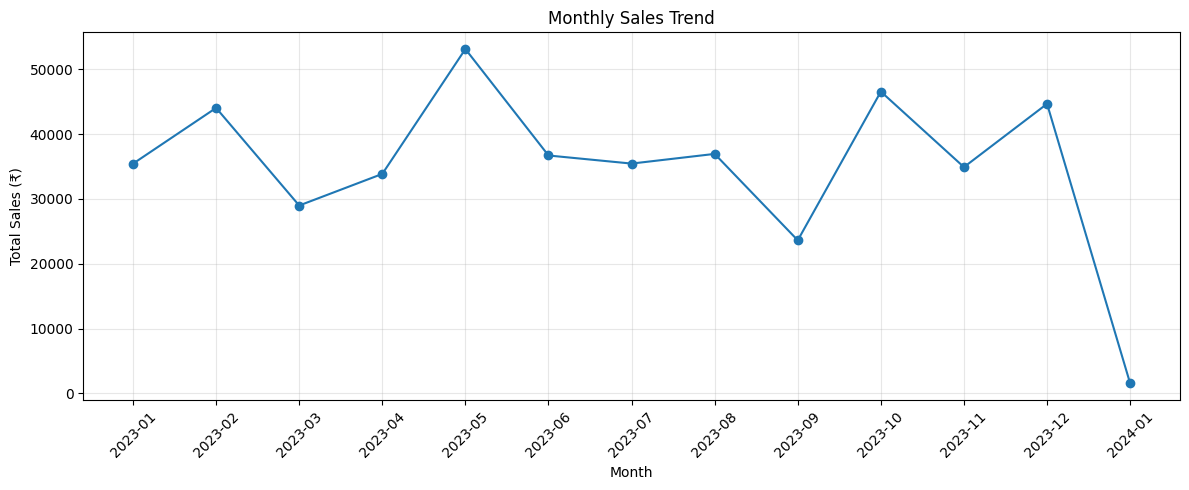

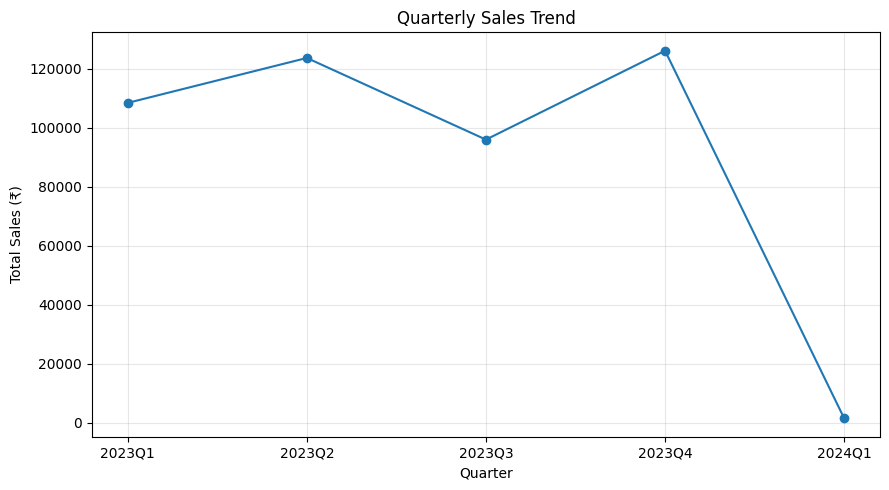

In [6]:

# Monthly sales trend
monthly_sales = (
    df.groupby(df['Date'].dt.to_period('M'))['Total Amount']
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Quarterly sales trend
quarterly_sales = (
    df.groupby(df['Date'].dt.to_period('Q'))['Total Amount']
    .sum()
)

plt.figure(figsize=(9, 5))
plt.plot(quarterly_sales.index.astype(str), quarterly_sales.values, marker='o')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales (₹)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Observations from Monthly and Quarterly Sales Trends

**Monthly Sales Trend**
- May 2023 recorded the highest monthly sales, at approximately ₹53,000.
- September 2023 recorded the lowest monthly sales among the months from January to December 2023, at approximately ₹24,000.
- Sales fluctuated throughout the year, with noticeable increases in May and October.
- January 2024 shows significantly lower sales than the previous months. This may be due to incomplete data for that month and should be verified before drawing conclusions.

**Quarterly Sales Trend**
- The fourth quarter of 2023 recorded the highest sales, at approximately ₹126,000.
- The third quarter recorded lower sales than the second and fourth quarters.
- The first quarter of 2024 shows very low sales, which may reflect incomplete data rather than an actual decline.

Overall, sales varied across months and quarters. Checking transaction coverage for each period is important before making business decisions.

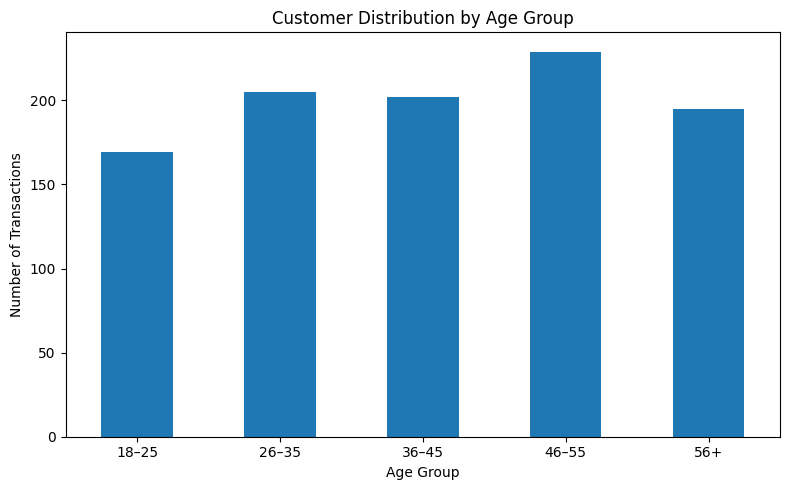

,Number of Transactions
Age Group,
18–25,169
26–35,205
36–45,202
46–55,229
56+,195


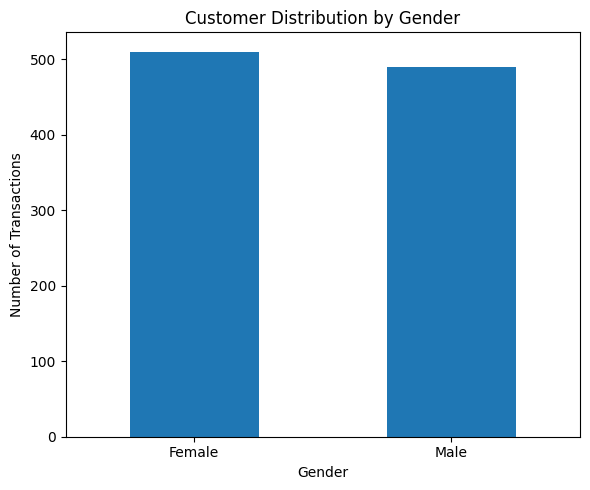

,Number of Transactions
Gender,
Female,510
Male,490


In [7]:

# Create customer age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 100],
    labels=['18–25', '26–35', '36–45', '46–55', '56+']
)

# Age group distribution
age_counts = df['Age Group'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
age_counts.plot(kind='bar')
plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(age_counts.to_frame(name='Number of Transactions'))


# Gender distribution
gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(6, 5))
gender_counts.plot(kind='bar')
plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(gender_counts.to_frame(name='Number of Transactions'))


### Observations from Customer Demographics

**Age Group Distribution**
- Customers aged 46–55 form the largest age group, with 229 transactions.
- Customers aged 26–35 account for 205 transactions, while those aged 36–45 account for 202.
- The 18–25 age group has the lowest number of transactions, at 169.
- Overall, transactions are distributed across all age groups, with a slightly higher representation of customers aged 46–55.

**Gender Distribution**
- Female customers account for 510 transactions (51%).
- Male customers account for 490 transactions (49%).
- The difference between the two groups is small, indicating a nearly balanced gender distribution.

**Business Insight:** Marketing campaigns could target different age groups with relevant product offers. Since the gender distribution is nearly balanced, the business should avoid focusing its overall marketing strategy on only one gender.

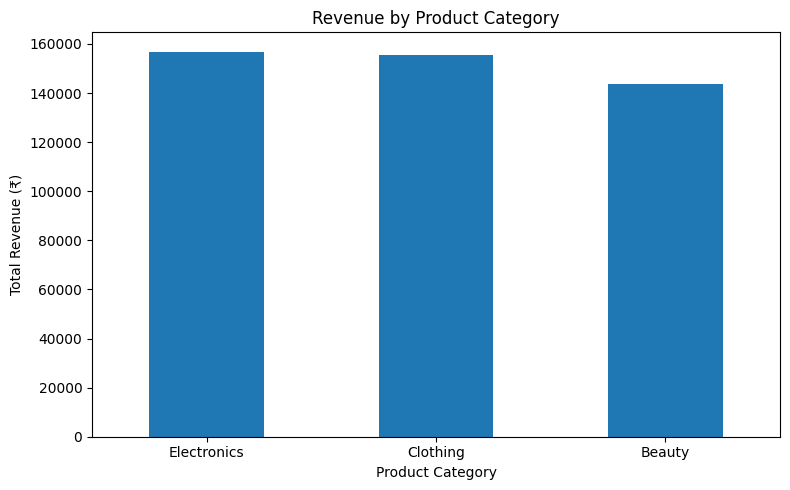

,Total Revenue (₹)
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


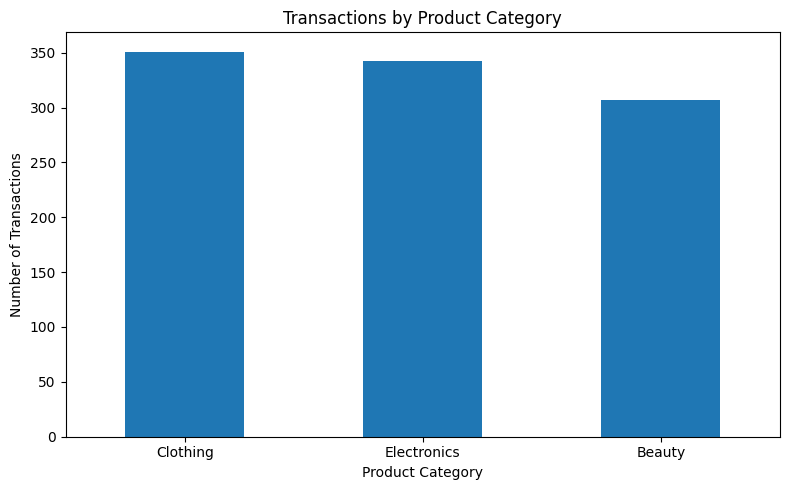

,Number of Transactions
Product Category,
Clothing,351
Electronics,342
Beauty,307


In [8]:

# Revenue by product category
category_revenue = (
    df.groupby('Product Category')['Total Amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
category_revenue.plot(kind='bar')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(category_revenue.to_frame(name='Total Revenue (₹)'))


# Number of transactions by product category
category_transactions = (
    df['Product Category']
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
category_transactions.plot(kind='bar')
plt.title('Transactions by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(category_transactions.to_frame(name='Number of Transactions'))


### Observations from Product Category Analysis

**Revenue by Product Category**
- Electronics generated the highest revenue at ₹156,905.
- Clothing followed closely with ₹155,580.
- Beauty generated the lowest revenue at ₹143,515.
- The revenue difference between Electronics and Clothing is only ₹1,325, indicating similar overall revenue contributions.

**Transactions by Product Category**
- Clothing recorded the highest number of transactions, with 351.
- Electronics recorded 342 transactions.
- Beauty had the lowest number of transactions, with 307.

**Business Insight:** Electronics generated the highest revenue despite having fewer transactions than Clothing. The business could examine pricing and purchasing patterns in Electronics to understand its revenue advantage. Beauty could be reviewed for opportunities to improve sales and customer engagement.

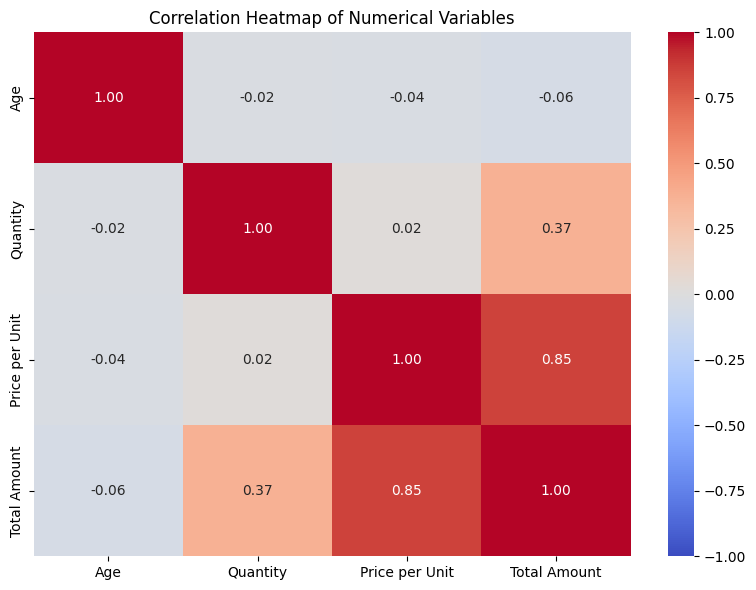

,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


In [9]:

# Select numerical columns, excluding Transaction ID
numerical_data = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))


### Observations from Correlation Analysis

- **Price per Unit and Total Amount (0.85):** A strong positive correlation exists between these variables. Higher unit prices are generally associated with higher transaction amounts.
- **Quantity and Total Amount (0.37):** These variables have a moderate positive correlation, suggesting that purchasing more units is generally associated with higher transaction amounts.
- **Age and Total Amount (-0.06):** The relationship is very weak, indicating little linear association between customer age and transaction amount in this dataset.
- **Age and Quantity (-0.02):** There is almost no linear correlation between customer age and quantity purchased.
- **Age and Price per Unit (-0.04):** There is almost no linear relationship between customer age and unit price.

Overall, transaction amount is more strongly associated with unit price than with quantity. Correlation indicates association, not causation.

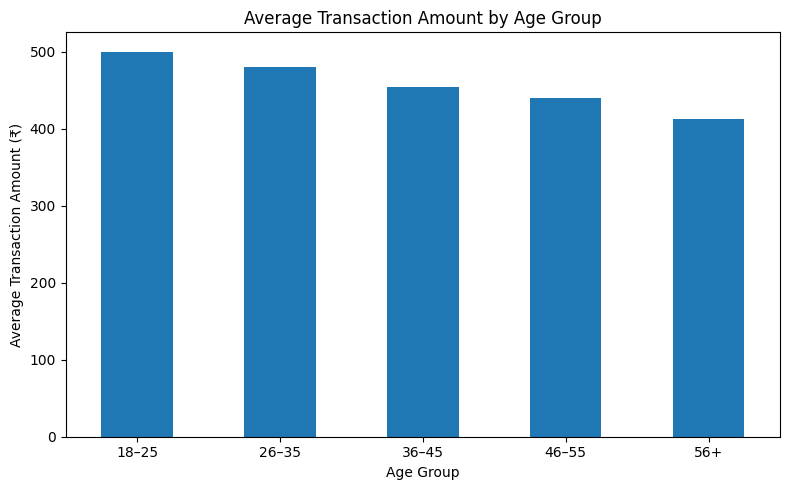

,Average Transaction Amount (₹)
Age Group,
18–25,500.30
26–35,480.39
36–45,454.80
46–55,439.69
56+,412.36


In [10]:

# Average transaction amount by age group
age_group_spending = (
    df.groupby('Age Group', observed=False)['Total Amount']
    .mean()
)

plt.figure(figsize=(8, 5))
age_group_spending.plot(kind='bar')
plt.title('Average Transaction Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    age_group_spending
    .round(2)
    .to_frame(name='Average Transaction Amount (₹)')
)


### Observations from Average Transaction Amount by Age Group

- Customers aged 18–25 have the highest average transaction amount at ₹500.30.
- The 26–35 age group follows with an average of ₹480.39.
- Customers aged 36–45 have an average transaction amount of ₹454.80.
- The 46–55 age group has an average of ₹439.69.
- Customers aged 56 and above have the lowest average transaction amount at ₹412.36.

**Business Insight:** In this dataset, younger age groups have higher average transaction amounts than older age groups. The business could investigate age-specific purchasing preferences and test targeted offers. These findings describe this dataset and should not automatically be generalized to all customers.

## Conclusion and Business Recommendations

### Conclusion

This exploratory data analysis examined 1,000 retail transactions to understand sales performance, customer demographics, product categories, and relationships between numerical variables. The dataset contained no missing values or duplicate rows, and the recorded transaction amounts matched the calculated quantity multiplied by unit price.

Electronics generated the highest revenue, while Clothing recorded the most transactions. Customer transactions were distributed across all age groups, and the gender split was nearly balanced. The correlation analysis showed a strong positive relationship between unit price and total transaction amount. The age-group spending analysis also showed higher average transaction amounts among younger customers in this dataset.

### Actionable Business Recommendations

1. **Strengthen Electronics sales:** Electronics generated the highest revenue at ₹156,905. Review its popular price points and purchasing patterns to identify opportunities for additional sales.
2. **Maintain Clothing's transaction volume:** Clothing recorded 351 transactions, the highest among the three categories. Test relevant promotions and product bundles to encourage additional purchases.
3. **Investigate Beauty category performance:** Beauty generated ₹143,515 in revenue and recorded 307 transactions. Examine customer feedback, pricing, and product preferences to identify opportunities to improve performance.
4. **Test age-specific marketing campaigns:** Younger age groups had higher average transaction amounts in this dataset. Test targeted offers and compare the results before expanding campaigns.
5. **Monitor sales trends consistently:** Track monthly and quarterly revenue, and verify whether each reporting period contains complete data before interpreting large changes as business trends.

### Dataset Limitation

The dataset contains product categories but does not include individual product names or identifiers. Therefore, the top 10 individual best-selling products could not be identified. January 2024 also contains unusually low recorded sales, so its data coverage should be verified before drawing conclusions about performance.